[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/udayRage/streamPAMI/blob/main/notebooks/frequentPattern/basic/LossyCounting.ipynb)

# Finding frequent itemsets in transaction streams with LossyCounting

This tutorial follows PAMI's progression: mine once, evaluate several support
thresholds, then feed batches as a live stream. Pattern supports are counts;
minSup is a fraction, unlike PAMI's optional absolute-count threshold.

[Algorithm documentation and accuracy limits](../../../docs/frequentPattern/basic/LossyCounting.md)

Locally, install the notebook tools in your virtual environment with
`pip install -e ".[notebooks]"` from the repository root, then select that
environment's Python kernel. Colab already supplies a notebook environment.


## Prerequisites

### Install only if needed

Keep an existing local installation, including an editable checkout. The
conditional installation below runs only if streamPAMI cannot be imported.


In [1]:
try:
    import streamPAMI
except ImportError:
    %pip install -q git+https://github.com/udayRage/streamPAMI


### Download a sample dataset

Use T10I4D100K, also used in the project's evaluation. Python's downloader
works on Windows and Colab. An existing local file is reused.


In [2]:
from pathlib import Path
from urllib.request import urlretrieve

data_path = Path("Transactional_T10I4D100K.csv")
data_url = "https://u-aizu.ac.jp/~udayrage/datasets/transactionalDatabases/Transactional_T10I4D100K.csv"
if not data_path.is_file():
    urlretrieve(data_url, data_path)
print("Dataset:", data_path.name)


Dataset: Transactional_T10I4D100K.csv


### Inspect the input

Each non-blank line is a transaction containing tab-separated item labels.
There is no header or transaction id. Blank file lines are skipped. The
filename is a dataset label; use the actual non-blank transaction count.


In [3]:
from itertools import islice

with data_path.open(encoding="utf-8") as source:
    for line in islice(source, 2):
        print(line.rstrip("\r\n"))
with data_path.open(encoding="utf-8") as source:
    transaction_count = sum(bool(line.strip()) for line in source)
print("Transactions:", transaction_count)


25	52	164	240	274	328	368	448	538	561	630	687	730	775	825	834
39	120	124	205	401	581	704	814	825	834
Transactions: 99935


## Part 1: Mining once

### Step 1: Choose parameters

Choose minSup = 0.006, epsilon = 0.0005 and batchSize = 10,000.
LossyCounting requires batch lengths to be multiples of ceil(1/epsilon).
Epsilon 0.0006 gives w = 1667, which does not divide 10,000;
epsilon 0.0005 gives w = 2000, which does.

The supplied file has 99,935 transactions. Its last batch has 9,935:
mine() processes 8,000 of these and holds 1,935 unprocessed.
The real UserWarning below reports the held suffix. Guarantees cover the
processed landmark stream, excluding the held transactions.


In [4]:
from streamPAMI.frequentPattern.basic.LossyCounting import LossyCounting

batch_size = 10000
min_sup = 0.006
epsilon = 0.0005
miner = LossyCounting(data_path, min_sup, epsilon, batch_size)


In [5]:
from fractions import Fraction
from math import ceil

for error in (0.0006, epsilon):
    bucket_width = ceil(1 / Fraction(str(error)))
    print("epsilon:", error, "bucket width:", bucket_width,
          "divides batchSize:", batch_size % bucket_width == 0)


epsilon: 0.0006 bucket width: 1667 divides batchSize: False
epsilon: 0.0005 bucket width: 2000 divides batchSize: True


### Step 2: Mine, print and save

The stored answer covers the whole processed landmark stream. Held transactions are excluded; reported counts are estimates. This implementation does not reproduce the paper's Buffer/Trie/SetGen data structures.

The saved format is `item1<tab>item2:support`.


In [6]:
miner.mine()
miner.printResults()
output_path = Path("LossyCounting_patterns.txt")
miner.save(output_path)


Total number of patterns: 899
Total time taken: 18.344196300022304
Total memory in USS: 140673024
Total memory in RSS: 164405248


<notebook cell>:1: UserWarning: Held 1935 transactions unprocessed because they do not fill a bucket of w=2000; they are excluded from the stream length and counts.
  miner.mine()


In [7]:
print("Processed transactions:", miner.getStreamLength())
print("Held transactions:", miner.getHeldCount())


Processed transactions: 98000
Held transactions: 1935


In [8]:
print("First saved pattern lines:")
with output_path.open(encoding="utf-8") as source:
    for line in islice(source, 5):
        print(line.rstrip("\r\n"))


First saved pattern lines:
0:584
616:556
794:612
436:581
430:574


In [9]:
miner.getPatternsAsDataFrame().head()


,Patterns,Support
0,0,584
1,616,556
2,794,612
3,436,581
4,430,574


## Part 2: Evaluating different minSup values

### Step 1: Choose thresholds and result columns

Rebuild and replay for each threshold; none of these miners accepts a
minSup argument at query time. Runtime is from mine(), including its final
query. RSS is the captured process memory reading in decimal MB, not a peak.


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
min_sups = [0.006, 0.007, 0.008, 0.009, 0.010]
rows = []


### Step 2: Execute and print the results

Keep epsilon = 0.0005 for every run so that whole buckets divide batchSize. Every replay holds the same 1,935 transactions; Python shows the warning only once for this loop.


In [11]:
for threshold in min_sups:
    candidate = LossyCounting(data_path, threshold, epsilon, batch_size)
    candidate.mine()
    rows.append({"algorithm": "LossyCounting", "minSup": threshold,
                 "patterns": len(candidate.getPatterns()),
                 "runtime_s": candidate.getRuntime(),
                 "memory_mb": candidate.getMemoryRSS() / 1000000})
results = pd.DataFrame(rows)
print(results.to_string(index=False))


<notebook cell>:3: UserWarning: Held 1935 transactions unprocessed because they do not fill a bucket of w=2000; they are excluded from the stream length and counts.
  candidate.mine()


    algorithm  minSup  patterns  runtime_s  memory_mb
LossyCounting   0.006       899  22.193998 217.178112
LossyCounting   0.007       675  23.061690 217.341952
LossyCounting   0.008       559  22.265598 219.987968
LossyCounting   0.009       446  22.320203 219.623424
LossyCounting   0.010       402  22.623316 220.536832


### Step 3: Visualise the results

These numbers come from sequential runs in one process and are for
illustration. They include process state retained from earlier cells.
Fair measurements are in [benchmarks/](../../../benchmarks/README.md) and
the [README Evaluation section](../../../README.md#evaluation), which
currently compare FP-Stream and DSTree with an exact baseline.


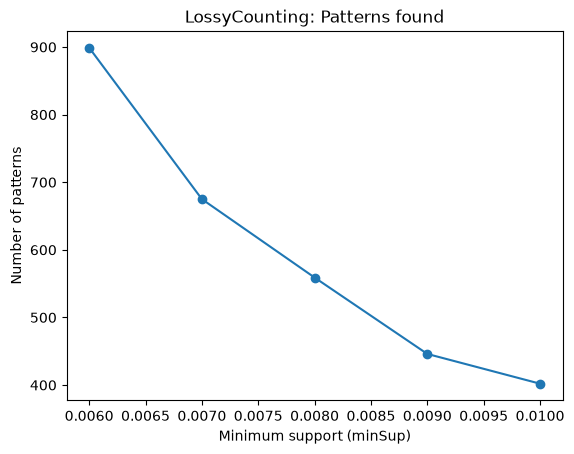

In [12]:
axis = results.plot(x="minSup", y="patterns", marker="o", legend=False,
                    title="LossyCounting: Patterns found")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Number of patterns")
plt.show()


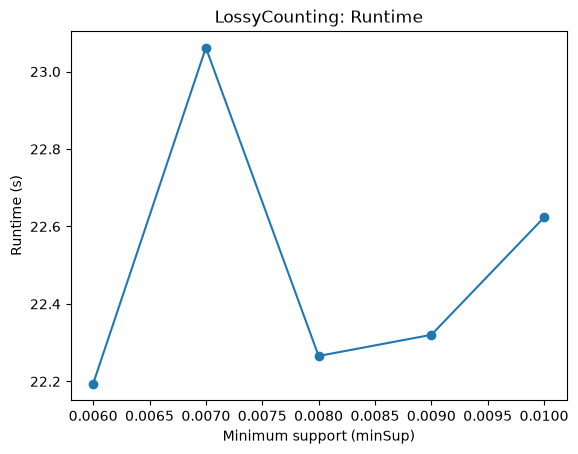

In [13]:
axis = results.plot(x="minSup", y="runtime_s", marker="o", legend=False,
                    title="LossyCounting: Runtime")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Runtime (s)")
plt.show()


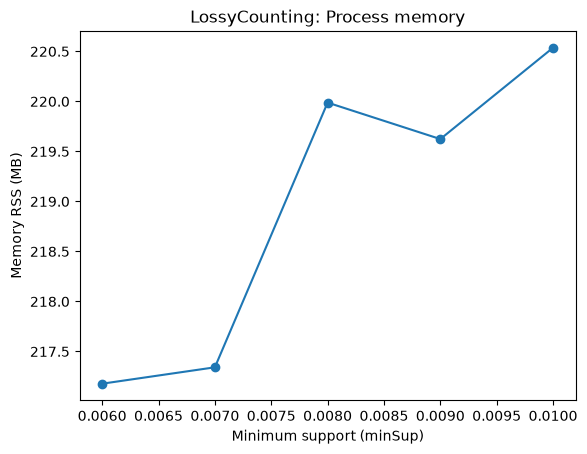

In [14]:
axis = results.plot(x="minSup", y="memory_mb", marker="o", legend=False,
                    title="LossyCounting: Process memory")
axis.set_xlabel("Minimum support (minSup)")
axis.set_ylabel("Memory RSS (MB)")
plt.show()


## Part 3: Using it as a live stream

Feed the first six full batches. The printed processing time measures only
processBatch(); the following query is outside that timer. queryPatterns()
returns the current answer; getPatterns() remains the last mine() result.


In [15]:
from time import perf_counter

def read_batches(path, size):
    batch = []
    with path.open(encoding="utf-8") as source:
        for line in source:
            line = line.strip()
            if not line:
                continue
            batch.append(line.split("\t"))
            if len(batch) == size:
                yield batch
                batch = []
    if batch:
        yield batch


In [16]:
live = LossyCounting(None, min_sup, epsilon, batch_size)
for batch_number, batch in enumerate(islice(read_batches(data_path, batch_size), 6), start=1):
    started = perf_counter()
    live.processBatch(batch)
    processing_s = perf_counter() - started
    patterns = live.queryPatterns()
    print(f"Batch {batch_number}: patterns={len(patterns)}, processing_s={processing_s:.6f}")
    print("Processed transactions:", live.getStreamLength())


Batch 1: patterns=1002, processing_s=2.162001
Processed transactions: 10000


Batch 2: patterns=887, processing_s=2.142982
Processed transactions: 20000


Batch 3: patterns=897, processing_s=2.252803
Processed transactions: 30000


Batch 4: patterns=909, processing_s=2.281538
Processed transactions: 40000


Batch 5: patterns=898, processing_s=2.365969
Processed transactions: 50000


Batch 6: patterns=900, processing_s=2.377735
Processed transactions: 60000


These batches all contain whole buckets, so the live loop processes
every transaction supplied. queryPatterns() takes no frame arguments:
it always covers the complete processed landmark stream.


In a real stream, append each broker message's transaction to the current
batch. Call processBatch when the batch is full, query when needed, then
start the next batch. Choose batch and query rates for the application's
latency and memory needs.

For LossyCounting, preserve whole-bucket lengths; keep an incomplete bucket buffered rather than counting it as processed.
